# Raster Forensics
This notebook is a simple exploration of a raster before diving into real sentinel data. Practised  creating a raster from an array, spatial orientation, bringin in CRS, affine transforms, etc. and examined how all these are inter connected.

The core idea is to understand the basics needed to scale into the intended outcome of the project objective - NDVI calculation, change detection etc.

In [27]:
import sys
print(sys.executable)

c:\Users\joyal\Projects\iris-lite\.venv\Scripts\python.exe


In [28]:
import numpy as np

data = np. array([
    [10, 20, 30],
    [40, 50, 60],
    [70, 80, 90]
])
print(data)
print(data.shape)

[[10 20 30]
 [40 50 60]
 [70 80 90]]
(3, 3)


In [29]:
import rasterio

In [30]:
from rasterio.transform import from_origin

transform = from_origin(
    500000,
    5700000,
    10,
    10
)

print(transform)

| 10.00, 0.00, 500000.00|
| 0.00,-10.00, 5700000.00|
| 0.00, 0.00, 1.00|


In [31]:
from pathlib import Path

output_path = Path("../data/processed/tiny_raster.tif")

with rasterio.open(
    output_path,
    "w",
    driver="GTiff",
    height=data.shape[0],
    width=data.shape[1],
    count=1,
    dtype=data.dtype,
    crs="EPSG:32632",
    transform=transform
) as dst:
    dst.write(data, 1)

In [32]:
with rasterio.open(output_path) as src:
    print("Width:", src.width)
    print("Height:", src.height)
    print("Band count:", src.count)
    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("Bounds:", src.bounds)
    print("Transform:")
    print(src.transform)

Width: 3
Height: 3
Band count: 1
CRS: EPSG:32632
Resolution: (10.0, 10.0)
Bounds: BoundingBox(left=500000.0, bottom=5699970.0, right=500030.0, top=5700000.0)
Transform:
| 10.00, 0.00, 500000.00|
| 0.00,-10.00, 5700000.00|
| 0.00, 0.00, 1.00|


In [33]:
with rasterio.open(output_path) as src:
    band1 = src.read(1)
print(band1)
print(type(band1))
print(band1.shape)
print(band1.dtype)

[[10 20 30]
 [40 50 60]
 [70 80 90]]
<class 'numpy.ndarray'>
(3, 3)
int64


In [34]:
with rasterio.open(output_path) as src:
    x, y = src.xy(1, 1)

print("X:", x)
print("Y:", y)

X: 500015.0
Y: 5699985.0


In [35]:
with rasterio.open(output_path) as src:
    row, col = src.index(500015, 5699985)

print("Row:", row)
print("Column:", col)
print("Value:", band1[row, col])

Row: 1
Column: 1
Value: 50


## Copernicus Catalogue Exploration

Before building the automated acquisition module, this section explores how Sentinel-2 observations are represented and discovered programmatically.

In [36]:
import requests

In [37]:
print(requests.__version__)

2.34.2


In [38]:
stac_url = 'https://stac.dataspace.copernicus.eu/v1/collections'
response = requests.get(stac_url)
print(response.status_code)
stac_dic = response.json()

200


In [39]:
stac_dic.keys()

dict_keys(['collections', 'links', 'numberMatched', 'numberReturned'])

In [40]:
ids = []

In [41]:
stac_dic['links'][0]['rel'] == 'next'

True

### Code for getting all ids

This the logic for getting all ids to pull respective data in the db

In [42]:
url = 'https://stac.dataspace.copernicus.eu/v1'
resp = requests.get(url)
stac_dic = resp.json()
print(stac_dic.keys())
print(stac_dic) # Check for pagination and link to get to the next set of data

dict_keys(['type', 'id', 'title', 'description', 'stac_version', 'conformsTo', 'links', 'stac_extensions'])
{'type': 'Catalog', 'id': 'cdse-stac', 'title': 'Copernicus Data Space Ecosystem (CDSE) asset-level STAC catalogue', 'description': 'A comprehensive and searchable catalog of Earth observation and scientific datasets that is actively maintained and updated by the Copernicus Data Space Ecosystem. The integrated STAC (SpatioTemporal Asset Catalog) API, which follows the open STAC specification, enables users to access detailed asset-level metadata, including spatial information, temporal coverage, and data specifications. This standardized interface facilitates efficient data discovery and retrieval across the extensive collection of environmental and scientific resources. More information: https://documentation.dataspace.copernicus.eu/', 'stac_version': '1.0.0', 'conformsTo': ['http://www.opengis.net/spec/cql2/1.0/conf/basic-cql2', 'http://www.opengis.net/spec/cql2/1.0/conf/cql2-j

In [43]:
stac_dic['links'][0]

{'rel': 'self',
 'type': 'application/json',
 'title': 'This document',
 'href': 'https://stac.dataspace.copernicus.eu/v1/'}

In [44]:
stac_dic

{'type': 'Catalog',
 'id': 'cdse-stac',
 'title': 'Copernicus Data Space Ecosystem (CDSE) asset-level STAC catalogue',
 'description': 'A comprehensive and searchable catalog of Earth observation and scientific datasets that is actively maintained and updated by the Copernicus Data Space Ecosystem. The integrated STAC (SpatioTemporal Asset Catalog) API, which follows the open STAC specification, enables users to access detailed asset-level metadata, including spatial information, temporal coverage, and data specifications. This standardized interface facilitates efficient data discovery and retrieval across the extensive collection of environmental and scientific resources. More information: https://documentation.dataspace.copernicus.eu/',
 'stac_version': '1.0.0',
 'conformsTo': ['http://www.opengis.net/spec/cql2/1.0/conf/basic-cql2',
  'http://www.opengis.net/spec/cql2/1.0/conf/cql2-json',
  'http://www.opengis.net/spec/cql2/1.0/conf/cql2-text',
  'http://www.opengis.net/spec/ogcapi-

In [ ]:
type(dict(stac_dic)['collections'][3])

dict

In [ ]:
for i in range(10):
    print(dict(stac_dic)['collections'][i]['id'])

ccm-atmospheric-ch4-hr
ccm-atmospheric-ch4-mr
ccm-atmospheric-rad-vhr
ccm-hyperspectral-ref-hr
ccm-hyperspectral-ref-vhr
ccm-optical
ccm-sar
ccm-thermal-lst-hr
ccm-thermal-lst-mr
clms_ba_global_300m_daily_v3_cog


In [ ]:
check = 'next'
url = stac_url
ids = []

while check == 'next':
    response = requests.get(url)
    stac_dic = response.json()
    for i in range(stac_dic['numberReturned']):
        ids.append(dict(stac_dic)['collections'][i]['id'])
    url = stac_dic['links'][0]['href']
    check = stac_dic['links'][0]['rel']


ids

['ccm-atmospheric-ch4-hr',
 'ccm-atmospheric-ch4-mr',
 'ccm-atmospheric-rad-vhr',
 'ccm-hyperspectral-ref-hr',
 'ccm-hyperspectral-ref-vhr',
 'ccm-optical',
 'ccm-sar',
 'ccm-thermal-lst-hr',
 'ccm-thermal-lst-mr',
 'clms_ba_global_300m_daily_v3_cog',
 'clms_ba_global_300m_daily_v3_nc',
 'clms_ba_global_300m_daily_v4_cog',
 'clms_ba_global_300m_daily_v4_nc',
 'clms_ba_global_300m_monthly_v3_cog',
 'clms_ba_global_300m_monthly_v3_nc',
 'clms_ba_global_300m_monthly_v4_cog',
 'clms_ba_global_300m_monthly_v4_nc',
 'clms_clcplus_lulucf-instance_europe_100m_yearly_v1',
 'clms_dmp_global_1km_10daily_v2_cog',
 'clms_dmp_global_1km_10daily_v2_nc',
 'clms_dmp_global_300m_10daily_v1_cog',
 'clms_dmp_global_300m_10daily_v1_nc',
 'clms_dmp_global_300m_10daily_v2_cog',
 'clms_dmp_global_300m_10daily_v2_nc',
 'clms_eta_global_300m_10daily_v1_cog',
 'clms_fapar_global_1km_10daily_v2_cog',
 'clms_fapar_global_1km_10daily_v2_nc',
 'clms_fapar_global_300m_10daily_v1_cog',
 'clms_fapar_global_300m_10daily

In [ ]:
stac_url_sentinel_l2a = 'https://stac.dataspace.copernicus.eu/v1/collections/sentinel-2-l2a'
# Got the id(sentinel-2-l2a)/extension in the url from the list ids
response = requests.get(stac_url_sentinel_l2a)
sent2_stac_dic = response.json()
sent2_stac_dic

{'id': 'sentinel-2-l2a',
 'type': 'Collection',
 'bands': [{'gsd': 60,
   'name': 'B01',
   'description': 'Coastal aerosol (band 1)',
   'eo:common_name': 'coastal'},
  {'gsd': 10,
   'name': 'B02',
   'description': 'Blue (band 2)',
   'eo:common_name': 'blue'},
  {'gsd': 10,
   'name': 'B03',
   'description': 'Green (band 3)',
   'eo:common_name': 'green'},
  {'gsd': 10,
   'name': 'B04',
   'description': 'Red (band 4)',
   'eo:common_name': 'red'},
  {'gsd': 20,
   'name': 'B05',
   'description': 'Red edge 1 (band 5)',
   'eo:common_name': 'rededge071'},
  {'gsd': 20,
   'name': 'B06',
   'description': 'Red edge 2 (band 6)',
   'eo:common_name': 'rededge075'},
  {'gsd': 20,
   'name': 'B07',
   'description': 'Red edge 3 (band 7)',
   'eo:common_name': 'rededge078'},
  {'gsd': 10,
   'name': 'B08',
   'description': 'NIR 1 (band 8)',
   'eo:common_name': 'nir'},
  {'gsd': 20,
   'name': 'B8A',
   'description': 'NIR 2 (band 8A)',
   'eo:common_name': 'nir08'},
  {'gsd': 60,
   

In [ ]:
stac_url_something_else = 'https://stac.dataspace.copernicus.eu/v1/collections/sentinel-6-p4-1b-ntc'
# Got the id(sentinel-6-p4-1b-ntc)/extension in the url from the list ids
response = requests.get(stac_url_something_else)
something_else_stac_dic = response.json()
something_else_stac_dic

{'id': 'sentinel-6-p4-1b-ntc',
 'type': 'Collection',
 'bands': [{'description': 'Ionospheric correction and surface roughness estimation',
   'sar:bandwidth': 0.32,
   'sar:frequency_band': 'C',
   'sar:center_frequency': 5.41},
  {'description': 'Primary altimetric measurements',
   'sar:bandwidth': 0.32,
   'sar:frequency_band': 'Ku',
   'sar:center_frequency': 13.575}],
 'links': [{'rel': 'items',
   'type': 'application/geo+json',
   'href': 'https://stac.dataspace.copernicus.eu/v1/collections/sentinel-6-p4-1b-ntc/items'},
  {'rel': 'parent',
   'type': 'application/json',
   'href': 'https://stac.dataspace.copernicus.eu/v1/'},
  {'rel': 'root',
   'type': 'application/json',
   'href': 'https://stac.dataspace.copernicus.eu/v1/'},
  {'rel': 'self',
   'type': 'application/json',
   'href': 'https://stac.dataspace.copernicus.eu/v1/collections/sentinel-6-p4-1b-ntc'},
  {'rel': 'license',
   'href': 'https://sentinel.esa.int/documents/247904/690755/Sentinel_Data_Legal_Notice',
   'ty

In [46]:
longitude = 12.41886
latitude = 51.15724

bbox = [
    longitude - 0.03,
    latitude - 0.03,
    longitude + 0.03,
    latitude + 0.03
]

search_url = "https://stac.dataspace.copernicus.eu/v1/search"

params = {
    "collections": ["sentinel-2-l2a"],
    "datetime": "2021-06-01T00:00:00Z/2021-06-30T23:59:59Z",
    "bbox": bbox,
    "limit": 100
}

response = requests.post(search_url, json=params)

print(response.status_code)

200


In [47]:
response.json()

{'type': 'FeatureCollection',
 'links': [{'rel': 'root',
   'type': 'application/json',
   'href': 'https://stac.dataspace.copernicus.eu/v1/'},
  {'rel': 'self',
   'type': 'application/json',
   'href': 'https://stac.dataspace.copernicus.eu/v1/search'}],
 'features': [{'id': 'S2B_MSIL2A_20210630T101559_N0500_R065_T33UUS_20230319T172945',
   'bbox': [12.123708231698876,
    50.42971299170202,
    13.713790901113914,
    51.44399790803582],
   'type': 'Feature',
   'links': [{'rel': 'collection',
     'type': 'application/json',
     'href': 'https://stac.dataspace.copernicus.eu/v1/collections/sentinel-2-l2a'},
    {'rel': 'parent',
     'type': 'application/json',
     'href': 'https://stac.dataspace.copernicus.eu/v1/collections/sentinel-2-l2a'},
    {'rel': 'root',
     'type': 'application/json',
     'href': 'https://stac.dataspace.copernicus.eu/v1/'},
    {'rel': 'self',
     'type': 'application/geo+json',
     'href': 'https://stac.dataspace.copernicus.eu/v1/collections/sentinel-

In [48]:
data = response.json()

print(data.keys())
print(type(data["features"]))
print(len(data["features"]))

first_item = data["features"][0]

print(first_item.keys())

dict_keys(['type', 'links', 'features', 'numberReturned'])
<class 'list'>
24
dict_keys(['id', 'bbox', 'type', 'links', 'assets', 'geometry', 'collection', 'properties', 'stac_extensions', 'stac_version'])


In [49]:
first_item["properties"]

{'gsd': 10,
 'created': '2023-06-09T22:12:47.660000Z',
 'expires': '2262-01-01T00:00:00.000000Z',
 'updated': '2026-09-28T19:50:31.524281Z',
 '_private': {'visible': True,
  'product_name': 'S2B_MSIL2A_20210630T101559_N0500_R065_T33UUS_20230319T172945.SAFE',
  'product_size': 924382795,
  'product_uuid': 'aa5cfbd6-a25b-48de-98d7-3252443faf97'},
 'datetime': '2021-06-30T10:15:59.024000Z',
 'platform': 'sentinel-2b',
 'grid:code': 'MGRS-33UUS',
 'published': '2023-06-09T23:13:49.044955Z',
 'statistics': {'water': 0.045836,
  'nodata': 5.705037,
  'dark_area': 0.036815,
  'vegetation': 3.4958030000000004,
  'thin_cirrus': 1.091103,
  'cloud_shadow': 0.12214000000000001,
  'unclassified': 0.97246,
  'not_vegetated': 0.178473,
  'high_proba_clouds': 74.380654,
  'medium_proba_clouds': 19.676712,
  'saturated_defective': 0.0},
 'instruments': ['msi'],
 'auth:schemes': {'s3': {'type': 's3'},
  'oidc': {'type': 'openIdConnect',
   'openIdConnectUrl': 'https://identity.dataspace.copernicus.eu/a

In [50]:
for item in data["features"]:
    print(
        item["properties"]["datetime"],
        item["properties"]["eo:cloud_cover"],
        item["id"]
    )

2021-06-30T10:15:59.024000Z 95.15 S2B_MSIL2A_20210630T101559_N0500_R065_T33UUS_20230319T172945
2021-06-30T10:15:59.024000Z 93.1 S2B_MSIL2A_20210630T101559_N0500_R065_T32UQB_20230319T172945
2021-06-27T10:05:59.024000Z 78.9 S2B_MSIL2A_20210627T100559_N0500_R022_T33UUS_20230318T220525
2021-06-27T10:05:59.024000Z 74.05 S2B_MSIL2A_20210627T100559_N0500_R022_T32UQB_20230318T220525
2021-06-25T10:20:21.024000Z 93.63 S2A_MSIL2A_20210625T102021_N0500_R065_T33UUS_20230319T054911
2021-06-25T10:20:21.024000Z 94.65 S2A_MSIL2A_20210625T102021_N0500_R065_T32UQB_20230319T054911
2021-06-22T10:10:31.024000Z 99.68 S2A_MSIL2A_20210622T101031_N0500_R022_T33UUS_20230129T153031
2021-06-22T10:10:31.024000Z 99.89 S2A_MSIL2A_20210622T101031_N0500_R022_T32UQB_20230129T153031
2021-06-20T10:15:59.024000Z 75.91 S2B_MSIL2A_20210620T101559_N0500_R065_T33UUS_20230308T092944
2021-06-20T10:15:59.024000Z 76.46 S2B_MSIL2A_20210620T101559_N0500_R065_T32UQB_20230308T092944
2021-06-17T10:05:59.026000Z 0.0 S2B_MSIL2A_20210617T

In [51]:
type(data)

dict

In [52]:
stac_results = response.json()

june17 = [
    item for item in stac_results["features"]
    if item["properties"]["datetime"].startswith("2021-06-17")
]

In [55]:
june17

[{'id': 'S2B_MSIL2A_20210617T100559_N0500_R022_T33UUS_20230321T221728',
  'bbox': [12.123708231698876,
   50.42971299170202,
   13.729300891794363,
   51.44399790803582],
  'type': 'Feature',
  'links': [{'rel': 'collection',
    'type': 'application/json',
    'href': 'https://stac.dataspace.copernicus.eu/v1/collections/sentinel-2-l2a'},
   {'rel': 'parent',
    'type': 'application/json',
    'href': 'https://stac.dataspace.copernicus.eu/v1/collections/sentinel-2-l2a'},
   {'rel': 'root',
    'type': 'application/json',
    'href': 'https://stac.dataspace.copernicus.eu/v1/'},
   {'rel': 'self',
    'type': 'application/geo+json',
    'href': 'https://stac.dataspace.copernicus.eu/v1/collections/sentinel-2-l2a/items/S2B_MSIL2A_20210617T100559_N0500_R022_T33UUS_20230321T221728'},
   {'rel': 'enclosure',
    'href': 's3://eodata/Sentinel-2/MSI/L2A_N0500/2021/06/17/S2B_MSIL2A_20210617T100559_N0500_R022_T33UUS_20230321T221728.SAFE/',
    'type': 'application/x-directory',
    'title': 'S3 

In [54]:
for item in june17:
    print(item["id"])
    print("bbox:", item["bbox"])
    print()

S2B_MSIL2A_20210617T100559_N0500_R022_T33UUS_20230321T221728
bbox: [12.123708231698876, 50.42971299170202, 13.729300891794363, 51.44399790803582]

S2B_MSIL2A_20210617T100559_N0500_R022_T32UQB_20230321T221728
bbox: [11.815510113566978, 50.38212225093181, 13.45058969901368, 51.411810118104945]



In [56]:
item_33 = june17[0]

item_33["assets"].keys()

dict_keys(['AOT_10m', 'AOT_20m', 'AOT_60m', 'B01_20m', 'B01_60m', 'B02_10m', 'B02_20m', 'B02_60m', 'B03_10m', 'B03_20m', 'B03_60m', 'B04_10m', 'B04_20m', 'B04_60m', 'B05_20m', 'B05_60m', 'B06_20m', 'B06_60m', 'B07_20m', 'B07_60m', 'B08_10m', 'B09_60m', 'B11_20m', 'B11_60m', 'B12_20m', 'B12_60m', 'B8A_20m', 'B8A_60m', 'CLD_20m', 'CLD_60m', 'Product', 'SCL_20m', 'SCL_60m', 'SNW_20m', 'SNW_60m', 'TCI_10m', 'TCI_20m', 'TCI_60m', 'WVP_10m', 'WVP_20m', 'WVP_60m', 'thumbnail', 'safe_manifest', 'granule_metadata', 'inspire_metadata', 'product_metadata', 'datastrip_metadata'])

In [57]:
item_32 = june17[1]

item_32["assets"].keys()

dict_keys(['AOT_10m', 'AOT_20m', 'AOT_60m', 'B01_20m', 'B01_60m', 'B02_10m', 'B02_20m', 'B02_60m', 'B03_10m', 'B03_20m', 'B03_60m', 'B04_10m', 'B04_20m', 'B04_60m', 'B05_20m', 'B05_60m', 'B06_20m', 'B06_60m', 'B07_20m', 'B07_60m', 'B08_10m', 'B09_60m', 'B11_20m', 'B11_60m', 'B12_20m', 'B12_60m', 'B8A_20m', 'B8A_60m', 'CLD_20m', 'CLD_60m', 'Product', 'SCL_20m', 'SCL_60m', 'SNW_20m', 'SNW_60m', 'TCI_10m', 'TCI_20m', 'TCI_60m', 'WVP_10m', 'WVP_20m', 'WVP_60m', 'thumbnail', 'safe_manifest', 'granule_metadata', 'inspire_metadata', 'product_metadata', 'datastrip_metadata'])

In [58]:
for key in ["B04_10m", "B08_10m", "SCL_20m"]:
    asset = item_33["assets"][key]

    print("\n", key)
    print("title:", asset.get("title"))
    print("gsd:", asset.get("gsd"))
    print("type:", asset.get("type"))
    print("roles:", asset.get("roles"))
    print("href:", asset.get("href"))


 B04_10m
title: Red (band 4) - 10m
gsd: 10
type: image/jp2
roles: ['data', 'reflectance', 'sampling:original', 'gsd:10m']
href: s3://eodata/Sentinel-2/MSI/L2A_N0500/2021/06/17/S2B_MSIL2A_20210617T100559_N0500_R022_T33UUS_20230321T221728.SAFE/GRANULE/L2A_T33UUS_A022356_20210617T101301/IMG_DATA/R10m/T33UUS_20210617T100559_B04_10m.jp2

 B08_10m
title: NIR 1 (band 8) - 10m
gsd: 10
type: image/jp2
roles: ['data', 'reflectance', 'sampling:original', 'gsd:10m']
href: s3://eodata/Sentinel-2/MSI/L2A_N0500/2021/06/17/S2B_MSIL2A_20210617T100559_N0500_R022_T33UUS_20230321T221728.SAFE/GRANULE/L2A_T33UUS_A022356_20210617T101301/IMG_DATA/R10m/T33UUS_20210617T100559_B08_10m.jp2

 SCL_20m
title: Scene classification map (SCL) - 20m
gsd: 20
type: image/jp2
roles: ['data', 'sampling:original', 'gsd:20m']
href: s3://eodata/Sentinel-2/MSI/L2A_N0500/2021/06/17/S2B_MSIL2A_20210617T100559_N0500_R022_T33UUS_20230321T221728.SAFE/GRANULE/L2A_T33UUS_A022356_20210617T101301/IMG_DATA/R20m/T33UUS_20210617T100559_SC

In [59]:
b04_asset = item_33["assets"]["B04_10m"]

b04_asset.keys()

dict_keys(['href', 'bands', 'roles', 'alternate', 'auth:refs', 'file:size', 'proj:bbox', 'proj:code', 'storage:refs', 'view:azimuth', 'file:checksum', 'proj:transform', 'file:local_path', 'view:incidence_angle', 'gsd', 'type', 'title', 'nodata', 'data_type', 'proj:shape', 'raster:scale', 'raster:offset', 'alternate:name'])

In [60]:
b04_asset["alternate"]

{'https': {'href': 'https://download.dataspace.copernicus.eu/odata/v1/Products(87617010-a67a-4f08-a484-a8299d10dc36)/Nodes(S2B_MSIL2A_20210617T100559_N0500_R022_T33UUS_20230321T221728.SAFE)/Nodes(GRANULE)/Nodes(L2A_T33UUS_A022356_20210617T101301)/Nodes(IMG_DATA)/Nodes(R10m)/Nodes(T33UUS_20210617T100559_B04_10m.jp2)/$value',
  'auth:refs': ['oidc'],
  'storage:refs': [],
  'alternate:name': 'HTTPS'}}

## Authenticated Data Access

In [61]:
import os
from dotenv import load_dotenv

load_dotenv("../.env")

username = os.environ["CDSE_USERNAME"]
password = os.environ["CDSE_PASSWORD"]

auth_url = (
    "https://identity.dataspace.copernicus.eu/"
    "auth/realms/CDSE/protocol/openid-connect/token"
)

auth_data = {
    "client_id": "cdse-public",
    "grant_type": "password",
    "username": username,
    "password": password,
}

auth_response = requests.post(auth_url, data=auth_data)

print(auth_response.status_code)

200


In [62]:
token_data = auth_response.json()

token_data.keys()

dict_keys(['access_token', 'expires_in', 'refresh_expires_in', 'refresh_token', 'token_type', 'not-before-policy', 'session_state', 'scope'])

In [63]:
access_token = token_data["access_token"]

print("Token received:", bool(access_token))

Token received: True


In [64]:
b04_url = item_33["assets"]["B04_10m"]["alternate"]["https"]["href"]

headers = {
    "Authorization": f"Bearer {access_token}"
}

In [65]:
from pathlib import Path

raw_dir = Path("../data/raw")
raw_dir.mkdir(parents=True, exist_ok=True)

b04_path = raw_dir / "2021-06-17_T33UUS_B04_10m.jp2"

with requests.get(b04_url, headers=headers, stream=True) as response:
    response.raise_for_status()

    with open(b04_path, "wb") as file:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                file.write(chunk)

print(b04_path)
print(f"{b04_path.stat().st_size / 1024**2:.1f} MB")

..\data\raw\2021-06-17_T33UUS_B04_10m.jp2
111.8 MB


## Real Sentinel-2 Raster Inspection

In [66]:
with rasterio.open(b04_path) as src:
    print("Driver:", src.driver)
    print("Width:", src.width)
    print("Height:", src.height)
    print("Band count:", src.count)
    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("Bounds:", src.bounds)
    print("Transform:", src.transform)
    print("Data type:", src.dtypes)

Driver: JP2OpenJPEG
Width: 10980
Height: 10980
Band count: 1
CRS: EPSG:32633
Resolution: (10.0, 10.0)
Bounds: BoundingBox(left=300000.0, bottom=5590200.0, right=409800.0, top=5700000.0)
Transform: | 10.00, 0.00, 300000.00|
| 0.00,-10.00, 5700000.00|
| 0.00, 0.00, 1.00|
Data type: ('uint16',)


In [67]:
with rasterio.open(b04_path) as src:
    sample = src.read(
        1,
        window=((5000, 5010), (5000, 5010))
    )

print(sample)
print("Shape:", sample.shape)
print("dtype:", sample.dtype)
print("Min:", sample.min())
print("Max:", sample.max())

[[1290 1302 1305 1276 1326 1294 1286 1320 1289 1300]
 [1298 1309 1309 1295 1322 1286 1288 1320 1285 1306]
 [1311 1320 1319 1300 1318 1294 1296 1298 1278 1304]
 [1391 1439 1508 1400 1374 1375 1415 1428 1384 1364]
 [1490 1451 1458 1456 1454 1423 1461 1516 1556 1490]
 [1646 1656 1604 1556 1449 1372 1492 1530 1583 1579]
 [1820 1792 1741 1620 1442 1394 1477 1519 1487 1486]
 [1814 1744 1672 1592 1460 1381 1398 1424 1428 1437]
 [1736 1646 1572 1550 1482 1390 1419 1427 1434 1449]
 [1654 1581 1539 1530 1467 1404 1401 1417 1437 1452]]
Shape: (10, 10)
dtype: uint16
Min: 1276
Max: 1820


In [68]:
reflectance = sample * 0.0001 - 0.1

print(reflectance)
print("Min reflectance:", reflectance.min())
print("Max reflectance:", reflectance.max())

[[0.029  0.0302 0.0305 0.0276 0.0326 0.0294 0.0286 0.032  0.0289 0.03  ]
 [0.0298 0.0309 0.0309 0.0295 0.0322 0.0286 0.0288 0.032  0.0285 0.0306]
 [0.0311 0.032  0.0319 0.03   0.0318 0.0294 0.0296 0.0298 0.0278 0.0304]
 [0.0391 0.0439 0.0508 0.04   0.0374 0.0375 0.0415 0.0428 0.0384 0.0364]
 [0.049  0.0451 0.0458 0.0456 0.0454 0.0423 0.0461 0.0516 0.0556 0.049 ]
 [0.0646 0.0656 0.0604 0.0556 0.0449 0.0372 0.0492 0.053  0.0583 0.0579]
 [0.082  0.0792 0.0741 0.062  0.0442 0.0394 0.0477 0.0519 0.0487 0.0486]
 [0.0814 0.0744 0.0672 0.0592 0.046  0.0381 0.0398 0.0424 0.0428 0.0437]
 [0.0736 0.0646 0.0572 0.055  0.0482 0.039  0.0419 0.0427 0.0434 0.0449]
 [0.0654 0.0581 0.0539 0.053  0.0467 0.0404 0.0401 0.0417 0.0437 0.0452]]
Min reflectance: 0.027600000000000013
Max reflectance: 0.08199999999999999


In [ ]:
b04_asset['.keys()']

dict_keys(['href', 'bands', 'roles', 'alternate', 'auth:refs', 'file:size', 'proj:bbox', 'proj:code', 'storage:refs', 'view:azimuth', 'file:checksum', 'proj:transform', 'file:local_path', 'view:incidence_angle', 'gsd', 'type', 'title', 'nodata', 'data_type', 'proj:shape', 'raster:scale', 'raster:offset', 'alternate:name'])

In [70]:
scale = b04_asset["raster:scale"]
offset = b04_asset["raster:offset"]

print("Scale:", scale)
print("Offset:", offset)

Scale: 0.0001
Offset: -0.1


In [71]:
reflectance = sample * scale + offset

print(reflectance)
print("Min reflectance:", reflectance.min())
print("Max reflectance:", reflectance.max())

[[0.029  0.0302 0.0305 0.0276 0.0326 0.0294 0.0286 0.032  0.0289 0.03  ]
 [0.0298 0.0309 0.0309 0.0295 0.0322 0.0286 0.0288 0.032  0.0285 0.0306]
 [0.0311 0.032  0.0319 0.03   0.0318 0.0294 0.0296 0.0298 0.0278 0.0304]
 [0.0391 0.0439 0.0508 0.04   0.0374 0.0375 0.0415 0.0428 0.0384 0.0364]
 [0.049  0.0451 0.0458 0.0456 0.0454 0.0423 0.0461 0.0516 0.0556 0.049 ]
 [0.0646 0.0656 0.0604 0.0556 0.0449 0.0372 0.0492 0.053  0.0583 0.0579]
 [0.082  0.0792 0.0741 0.062  0.0442 0.0394 0.0477 0.0519 0.0487 0.0486]
 [0.0814 0.0744 0.0672 0.0592 0.046  0.0381 0.0398 0.0424 0.0428 0.0437]
 [0.0736 0.0646 0.0572 0.055  0.0482 0.039  0.0419 0.0427 0.0434 0.0449]
 [0.0654 0.0581 0.0539 0.053  0.0467 0.0404 0.0401 0.0417 0.0437 0.0452]]
Min reflectance: 0.027600000000000013
Max reflectance: 0.08199999999999999


In [72]:
b08_asset = item_33["assets"]["B08_10m"]
b08_url = b08_asset["alternate"]["https"]["href"]

b08_path = raw_dir / "2021-06-17_T33UUS_B08_10m.jp2"

with requests.get(b08_url, headers=headers, stream=True) as response:
    response.raise_for_status()

    with open(b08_path, "wb") as file:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                file.write(chunk)

print(b08_path)
print(f"{b08_path.stat().st_size / 1024**2:.1f} MB")

..\data\raw\2021-06-17_T33UUS_B08_10m.jp2
129.3 MB


In [73]:
with rasterio.open(b04_path) as red_src, rasterio.open(b08_path) as nir_src:
    print("Same CRS:", red_src.crs == nir_src.crs)
    print("Same resolution:", red_src.res == nir_src.res)
    print("Same dimensions:", red_src.shape == nir_src.shape)
    print("Same transform:", red_src.transform == nir_src.transform)
    print("Same bounds:", red_src.bounds == nir_src.bounds)

Same CRS: True
Same resolution: True
Same dimensions: True
Same transform: True
Same bounds: True


In [77]:
with rasterio.open(b08_path) as src:
    nir_sample = src.read(
        1,
        window=((5000, 5010), (5000, 5010))
    )

print(nir_sample)
print("Min:", nir_sample.min())
print("Max:", nir_sample.max())

[[6493 6509 6384 6512 6472 6593 6596 6524 6400 6361]
 [6536 6507 6424 6613 6524 6701 6595 6532 6468 6423]
 [6480 6435 6396 6508 6595 6712 6625 6532 6524 6504]
 [6224 5914 5848 6149 6271 6373 6333 6260 6264 6268]
 [5925 5844 5753 5764 5816 6010 6025 5920 5928 5953]
 [5420 5398 5376 5303 5056 5255 5979 5855 5656 5659]
 [5629 5624 5241 5328 5244 5629 6332 6252 6208 6245]
 [5952 5917 5604 5993 5997 6264 6556 6471 6416 6549]
 [6152 6030 6174 6534 6354 6348 6506 6527 6444 6492]
 [6023 6167 6548 6624 6152 6258 6640 6547 6508 6507]]
Min: 5056
Max: 6712


In [78]:
nir_scale = b08_asset["raster:scale"]
nir_offset = b08_asset["raster:offset"]

print("Scale:", nir_scale)
print("Offset:", nir_offset)

Scale: 0.0001
Offset: -0.1


In [79]:
red = sample.astype("float32") * scale + offset
nir = nir_sample.astype("float32") * nir_scale + nir_offset

In [80]:
ndvi = (nir - red) / (nir + red)

print(ndvi)
print("Min NDVI:", ndvi.min())
print("Max NDVI:", ndvi.max())
print("Mean NDVI:", ndvi.mean())

[[0.89970607 0.89605916 0.89277554 0.9046303  0.8875475  0.90011895
  0.90275425 0.89048594 0.89840055 0.89401174]
 [0.89784026 0.89374137 0.89220303 0.9001354  0.8898393  0.9044597
  0.9020907  0.89063567 0.90092117 0.893175  ]
 [0.892592   0.88879234 0.88836396 0.8966943  0.8924405  0.90209794
  0.9000168  0.89777017 0.9041709  0.89531684]
 [0.86073023 0.8359799  0.8103062  0.85582983 0.86749333 0.86951977
  0.85560197 0.8495077  0.8640227  0.8707386 ]
 [0.8190212  0.8296506  0.824218   0.8252874  0.827704   0.84428495
  0.8319358  0.8101545  0.7972283  0.81995225]
 [0.74496645 0.7404036  0.75742966 0.77114636 0.8006659  0.83920467
  0.8201426  0.8031569  0.77743846 0.77892333]
 [0.6990274  0.70753324 0.70252913 0.74939364 0.81135297 0.84312165
  0.8357721  0.8201352  0.8289728  0.83039606]
 [0.7176552  0.73714894 0.7452616  0.78800356 0.8314092  0.86501324
  0.8663084  0.85614926 0.8535249  0.8539927 ]
 [0.75       0.7723749  0.800905   0.8191979  0.83481836 0.86406416
  0.85856545 

In [81]:
from rasterio.warp import transform

xs, ys = transform(
    "EPSG:4326",
    "EPSG:32633",
    [longitude],
    [latitude]
)

x = xs[0]
y = ys[0]

print("UTM X:", x)
print("UTM Y:", y)

UTM X: 319508.28045068425
UTM Y: 5670478.280638699


In [82]:
with rasterio.open(b04_path) as src:
    row, col = src.index(x, y)

print("Row:", row)
print("Column:", col)

Row: 2952
Column: 1950


In [83]:
half_size = 50

window = (
    (row - half_size, row + half_size),
    (col - half_size, col + half_size)
)

with rasterio.open(b04_path) as red_src:
    red_raw = red_src.read(1, window=window)

with rasterio.open(b08_path) as nir_src:
    nir_raw = nir_src.read(1, window=window)

print("Red shape:", red_raw.shape)
print("NIR shape:", nir_raw.shape)

Red shape: (100, 100)
NIR shape: (100, 100)


In [84]:
red = (
    red_raw.astype("float32")
    * b04_asset["raster:scale"]
    + b04_asset["raster:offset"]
)

nir = (
    nir_raw.astype("float32")
    * b08_asset["raster:scale"]
    + b08_asset["raster:offset"]
)

In [85]:
import numpy as np

denominator = nir + red

ndvi = np.full(red.shape, np.nan, dtype="float32")

valid = denominator != 0

ndvi[valid] = (
    (nir[valid] - red[valid])
    / denominator[valid]
)

print("Min NDVI:", np.nanmin(ndvi))
print("Max NDVI:", np.nanmax(ndvi))
print("Mean NDVI:", np.nanmean(ndvi))

Min NDVI: 0.07135366
Max NDVI: 0.91171587
Mean NDVI: 0.5421866


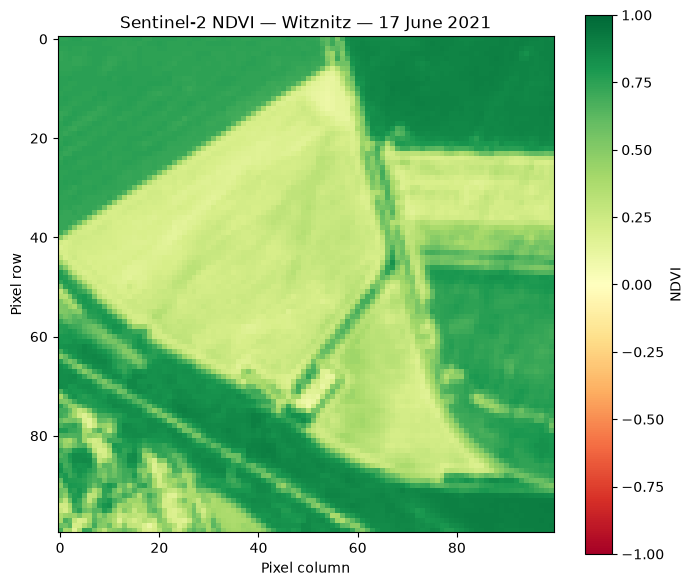

In [87]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 7))
plt.imshow(ndvi, cmap="RdYlGn", vmin=-1, vmax=1)
plt.colorbar(label="NDVI")
plt.title("Sentinel-2 NDVI — Witznitz — 17 June 2021")
plt.xlabel("Pixel column")
plt.ylabel("Pixel row")
plt.show()

In [89]:
auth_response = requests.post(auth_url, data=auth_data)
print(auth_response.status_code)

200


In [91]:
token_data = auth_response.json()
access_token = token_data["access_token"]

headers = {
    "Authorization": f"Bearer {access_token}"
}

print("New token received:", bool(access_token))

New token received: True


In [92]:
with requests.get(scl_url, headers=headers, stream=True) as response:
    print("Download status:", response.status_code)
    response.raise_for_status()

    with open(scl_path, "wb") as file:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                file.write(chunk)

print(scl_path)
print(f"{scl_path.stat().st_size / 1024**2:.1f} MB")

Download status: 200
..\data\raw\2021-06-17_T33UUS_SCL_20m.jp2
1.6 MB


In [93]:
with rasterio.open(scl_path) as src:
    print("Driver:", src.driver)
    print("Width:", src.width)
    print("Height:", src.height)
    print("Band count:", src.count)
    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("Bounds:", src.bounds)
    print("Transform:", src.transform)
    print("Data type:", src.dtypes)

Driver: JP2OpenJPEG
Width: 5490
Height: 5490
Band count: 1
CRS: EPSG:32633
Resolution: (20.0, 20.0)
Bounds: BoundingBox(left=300000.0, bottom=5590200.0, right=409800.0, top=5700000.0)
Transform: | 20.00, 0.00, 300000.00|
| 0.00,-20.00, 5700000.00|
| 0.00, 0.00, 1.00|
Data type: ('uint8',)


In [94]:
with rasterio.open(b04_path) as red_src:
    ndvi_transform = red_src.window_transform(window)
    ndvi_crs = red_src.crs

print(ndvi_transform)

| 10.00, 0.00, 319000.00|
| 0.00,-10.00, 5670980.00|
| 0.00, 0.00, 1.00|


In [95]:
from rasterio.warp import reproject
from rasterio.enums import Resampling

scl_aligned = np.empty(
    ndvi.shape,
    dtype="uint8"
)

with rasterio.open(scl_path) as scl_src:
    reproject(
        source=rasterio.band(scl_src, 1),
        destination=scl_aligned,

        src_transform=scl_src.transform,
        src_crs=scl_src.crs,

        dst_transform=ndvi_transform,
        dst_crs=ndvi_crs,

        resampling=Resampling.nearest
    )

print("SCL aligned shape:", scl_aligned.shape)
print("Classes present:", np.unique(scl_aligned))

SCL aligned shape: (100, 100)
Classes present: [4 5]


In [96]:
vegetation_ndvi = ndvi[scl_aligned == 4]
nonvegetation_ndvi = ndvi[scl_aligned == 5]

print(
    "Vegetation:",
    "pixels =", len(vegetation_ndvi),
    "mean NDVI =", np.nanmean(vegetation_ndvi)
)

print(
    "Not vegetated:",
    "pixels =", len(nonvegetation_ndvi),
    "mean NDVI =", np.nanmean(nonvegetation_ndvi)
)

Vegetation: pixels = 6068 mean NDVI = 0.7296328
Not vegetated: pixels = 3932 mean NDVI = 0.25291318


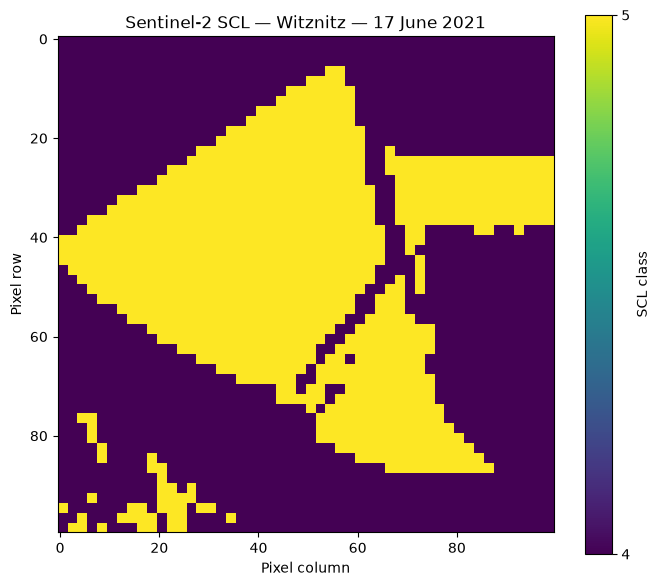

In [97]:
plt.figure(figsize=(8, 7))

plt.imshow(scl_aligned, vmin=4, vmax=5)
plt.colorbar(label="SCL class", ticks=[4, 5])

plt.title("Sentinel-2 SCL — Witznitz — 17 June 2021")
plt.xlabel("Pixel column")
plt.ylabel("Pixel row")

plt.show()